# Walkthrough: from yield curves to climate spreads

This notebook runs the pipeline stage by stage and shows the intermediate objects behind the published results. It executes top to bottom in a clean kernel; every number it prints is also written to `results/tables/` by `climate-risk run`. The equations are in [`docs/methodology.md`](../docs/methodology.md).

Without the licensed CDS panel (`$CLIMATE_RISK_CDS_PATH` or `data/private/cds.csv`) the credit stage runs in *demo mode*.

In [1]:
import io
import logging
from dataclasses import replace

import numpy as np
import pandas as pd
from IPython.display import Image, display

from climate_risk import figures
from climate_risk.config import Config
from climate_risk.data import scenarios
from climate_risk.figures.style import LIGHT, themed
from climate_risk.pipeline import Results, credit, portfolio, rates

logging.basicConfig(level=logging.ERROR)  # issuer-level messages stay out of the outputs
pd.set_option("display.precision", 3)

cfg = Config()
frame = scenarios.load_scenarios(cfg.paths.scenarios_csv)
print("credit data:", "licensed CDS panel" if cfg.paths.cds_csv.exists() else "DEMO mode")

credit data: licensed CDS panel


## 1. Term structure

Nelson–Siegel factors with one decay parameter, a shifting endpoint $i^*_t = r^*_t + \pi^*_t$ and a VAR(1) on the cycle.

In [2]:
rates_res = rates.run(cfg, frame)
rate_tables = rates.tables(cfg, frame, rates_res)
display(rate_tables["rates_summary"])
display(rate_tables["cycle_var_modes"])

,value
lambda_per_year,0.473
curvature_peak_years,3.791
months,489.000
rstar_jump_off,1.009
expected_inflation_jump_off,2.582
istar_jump_off,3.591


eigenvalue_modulus  half_life_months
model                            mode                                      
Shifting-endpoint VAR(1) (cycle) 1                  0.989            61.666
                                 2                  0.945            12.188
                                 3                  0.921             8.419
Constant-mean VAR(1) (betas)     1                  0.992            86.174
                                 2                  0.979            33.296
                                 3                  0.888             5.860

The pooled fit error is almost flat in $\lambda$ and has two minima. The global one puts the curvature hump at 15 years and destroys the level/slope interpretation, so the search is restricted to a medium-term third factor.

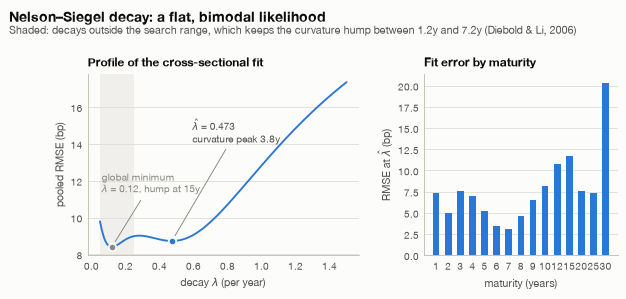

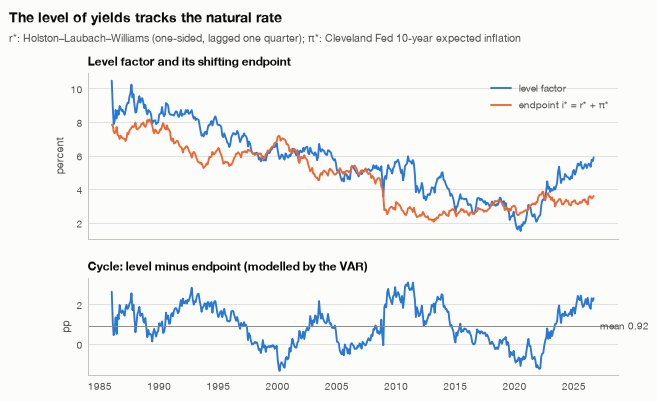

In [3]:
def show(factory) -> None:
    """Render one figure inline (light theme) as a PNG."""
    with themed(LIGHT):
        fig = factory(results, LIGHT)
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=90, bbox_inches="tight")
    display(Image(buffer.getvalue()))


# Results container for the figure functions (credit and portfolio filled in below).
results = Results(config=cfg, rates=rates_res, credit=None, portfolio=None, tables=rate_tables)
show(figures.rates_figures.lambda_profile)
show(figures.rates_figures.endpoint_history)

### Out-of-sample check

RMSE relative to the random walk (values below 1 beat it).

maturity                   2.0                                10.0         \
horizon                      1      6      12     24     60     1      6    
model                                                                       
Random walk               1.000  1.000  1.000  1.000  1.000  1.000  1.000   
DNS AR(1)                 1.121  1.156  1.146  1.082  1.177  0.985  1.094   
DNS VAR(1)                1.071  1.055  1.050  1.038  1.016  0.989  1.029   
Shifting-endpoint VAR(1)  1.097  1.103  1.076  0.984  0.974  1.008  1.126   

maturity                                       
horizon                      12     24     60  
model                                          
Random walk               1.000  1.000  1.000  
DNS AR(1)                 1.193  1.228  1.377  
DNS VAR(1)                1.076  1.082  1.123  
Shifting-endpoint VAR(1)  1.181  1.072  1.049

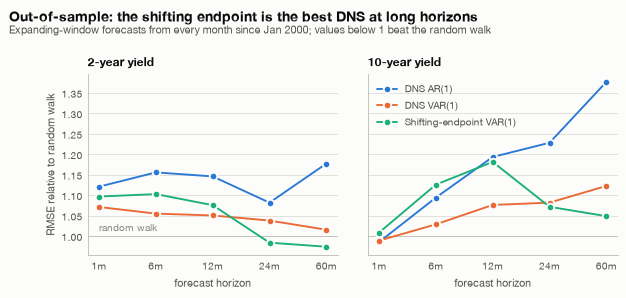

In [4]:
display(rate_tables["backtest_relative_rmse"].loc[:, [2.0, 10.0]].unstack("horizon"))
show(figures.rates_figures.backtest)

### Scenario-conditional endpoints

Scenarios move $r^*$ through their growth differential with SSP2-Baseline ($\theta = 1.113$), and the short rate through the carbon-price inflation impulse ($\kappa = 1.5$).

In [5]:
paths = rate_tables["endpoint_paths"]
years = [2030, 2040, 2050, 2100]
subset = paths.loc[
    (["SSP2 - Baseline", "SSP2 - 1.9", "SSP3 - Baseline", "SSP5 - Baseline"], years),
    ["growth", "rstar", "carbon_inflation", "slope_shift"],
]
display(subset)

growth  rstar  carbon_inflation  slope_shift
scenario        year                                              
SSP2 - Baseline 2030   2.208  1.009             0.000        0.000
                2040   1.811  1.009             0.000        0.000
                2050   1.696  1.009             0.000        0.000
                2100   1.702  1.009             0.000        0.000
SSP2 - 1.9      2030   2.172  0.968             0.061        0.092
                2040   1.742  0.932             0.098        0.147
                2050   1.627  0.932            -0.013       -0.019
                2100   1.651  0.952             0.130        0.194
SSP3 - Baseline 2030   1.971  0.744             0.000        0.000
                2040   0.832 -0.081             0.000        0.000
                2050   0.311 -0.533             0.000        0.000
                2100   0.520 -0.307             0.000        0.000
SSP5 - Baseline 2030   2.640  1.490             0.000        0.000
                2040   2.920  2.243             0.000        0.000
                2050   2.808  2.247             0.000        0.000
                2100   2.148  1.505             0.000        0.000

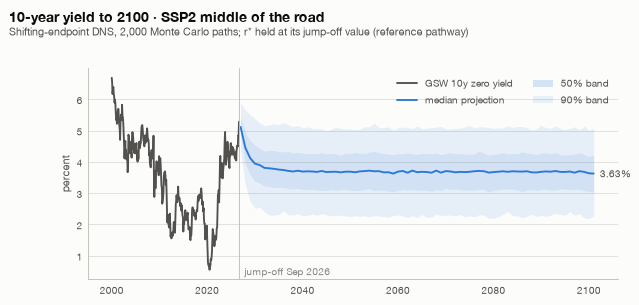

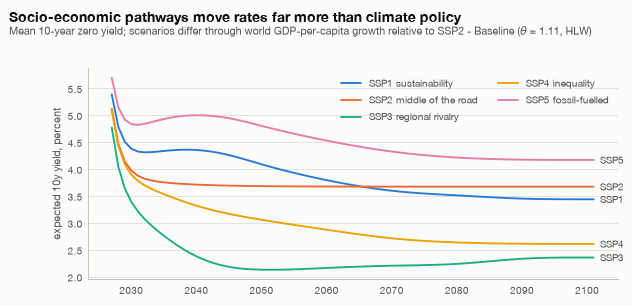

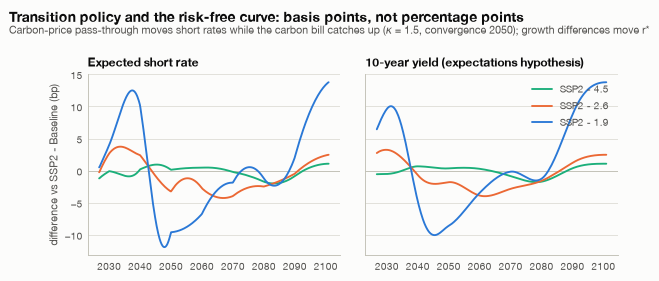

In [6]:
show(lambda r, t: figures.rates_figures.fan_10y(r, t, cfg.scenarios.reference))
show(lambda r, t: figures.rates_figures.narratives(r, t, cfg.scenarios.narratives))
baseline, headline = cfg.scenarios.headline
policies = tuple(p for p in cfg.scenarios.policy_family if p != baseline)
show(lambda r, t: figures.rates_figures.policy_channels(r, t, baseline, policies))

## 2. Climate spreads

Sector-median CDS curves are bootstrapped into risk-neutral default probabilities. Merton gives the asset volatility, and the Battiston–Monasterolo shock shifts the default threshold.

In [7]:
credit_res = credit.run(cfg, frame, rates_res)
credit_tables = credit.tables(credit_res)
display(credit_tables["credit_calibration"].T)

sector,Oil & gas,Utilities,Low-carbon control
cds_PX1_bp,15.492,12.53,7.897
cds_PX2_bp,29.027,21.367,13.582
cds_PX3_bp,43.578,31.462,19.928
cds_PX4_bp,60.933,46.962,27.648
cds_PX5_bp,72.87,61.45,37.062
cds_PX6_bp,86.498,70.953,45.138
cds_PX7_bp,94.824,80.34,51.888
cds_PX8_bp,100.105,85.37,57.43
cds_PX9_bp,104.072,90.267,61.258
cds_PX10_bp,108.803,95.062,65.028


In [8]:
spreads = credit_tables["climate_spreads"]
central = spreads[np.isclose(spreads["chi"], cfg.credit.chi)]
display(
    central.pivot_table(index=["policy", "sector"], columns="tenor", values="climate_spread_bp")[
        [1.0, 5.0, 10.0, 30.0]
    ]
)

tenor                           1.0     5.0     10.0    30.0
policy     sector                                           
SSP1 - 1.9 Low-carbon control -0.095  -1.808  -4.412  -2.028
           Oil & gas           6.271  37.958  59.683  38.836
           Utilities           7.316  43.818  58.569  32.411
SSP1 - 2.6 Low-carbon control -0.028  -0.425  -1.392  -0.970
           Oil & gas           1.000   8.724  16.632  19.221
           Utilities           1.119   9.566  17.957  21.374
SSP2 - 1.9 Low-carbon control -0.019  -0.479  -1.894   0.087
           Oil & gas           4.153  32.411  59.374  56.377
           Utilities           3.894  10.041  -7.292 -30.111
SSP2 - 2.6 Low-carbon control -0.004  -0.288  -0.812  -0.253
           Oil & gas           0.718   5.344  10.767  22.338
           Utilities           0.683   1.195  -3.694 -12.126
SSP2 - 4.5 Low-carbon control  0.021   0.070   0.165  -0.023
           Oil & gas           0.040   0.093  -0.267   1.952
           Utilities           0.172   0.526  -0.240  -2.366
SSP5 - 1.9 Low-carbon control -0.040  -0.214  -1.287   4.054
           Oil & gas           2.769  28.287  67.116  72.816
           Utilities           4.442  23.106   7.160 -38.772
SSP5 - 2.6 Low-carbon control -0.035  -0.294  -1.468   1.025
           Oil & gas           0.417   8.910  17.263  34.463
           Utilities           1.140   6.240   2.333 -24.620

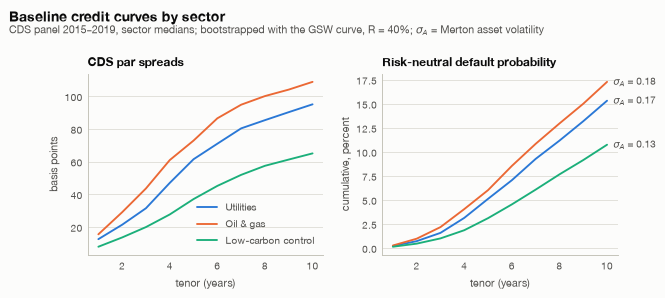

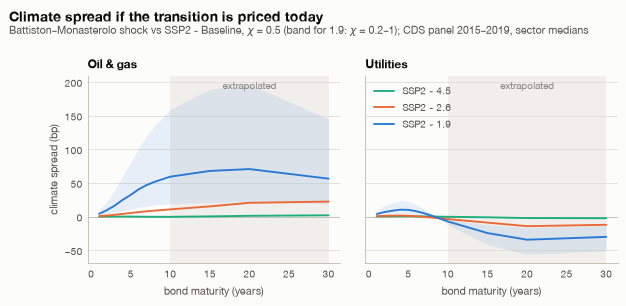

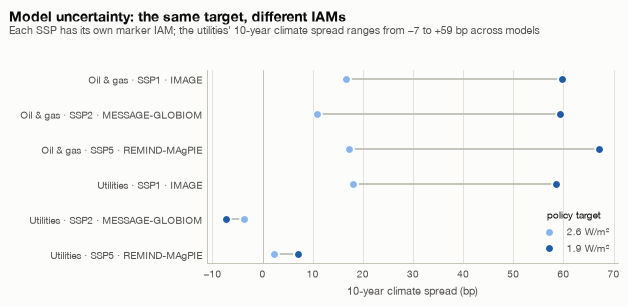

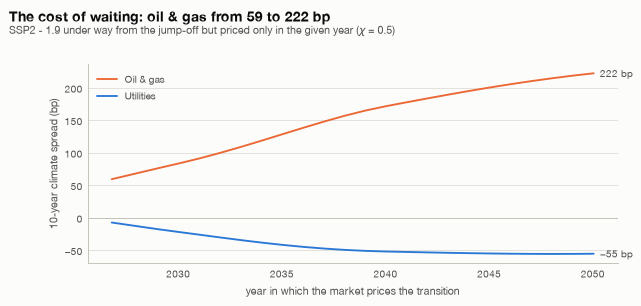

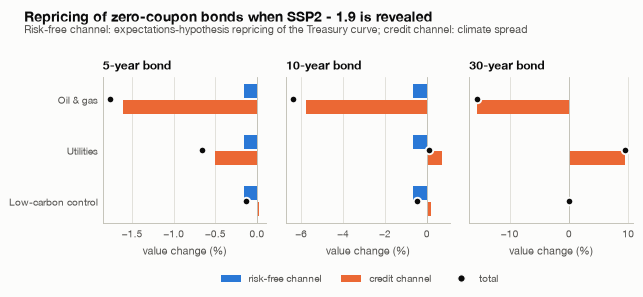

In [9]:
results = replace(results, credit=credit_res, tables={**rate_tables, **credit_tables})
show(figures.credit_figures.credit_reference)
show(lambda r, t: figures.credit_figures.climate_spreads(r, t, baseline))
show(figures.credit_figures.iam_uncertainty)
show(lambda r, t: figures.credit_figures.delayed_revelation(r, t, headline))
show(lambda r, t: figures.credit_figures.bond_value(r, t, headline))

## 3. Portfolio losses

The t-copula is calibrated on weekly CDS co-movements (Kendall's τ, ν by pseudo-maximum likelihood). Physical PDs use Driessen's risk-premium ratio.

In [10]:
portfolio_res = portfolio.run(cfg, frame, credit_res, rates_res)
portfolio_tables = portfolio.tables(portfolio_res)
display(portfolio_tables["portfolio_correlation_blocks"])
risk = portfolio_tables["portfolio_risk"]
display(
    risk[risk["measure"] == "Physical"].pivot_table(index="scenario", columns="copula", values="es")
)

,Low-carbon control,Utilities,Oil & gas
Low-carbon control,0.312,0.355,0.312
Utilities,0.355,0.458,0.411
Oil & gas,0.312,0.411,0.502


copula,Gaussian (Basel IRB ρ),Gaussian (CDS),Student t (CDS)
scenario,,,
Baseline (market-implied),0.125,0.203,0.239
SSP1 - 1.9,0.159,0.251,0.283
SSP1 - 2.6,0.134,0.215,0.251
SSP2 - 1.9,0.142,0.227,0.261
SSP2 - 2.6,0.128,0.207,0.242
SSP2 - 4.5,0.126,0.203,0.239
SSP5 - 1.9,0.147,0.234,0.269
SSP5 - 2.6,0.132,0.213,0.248


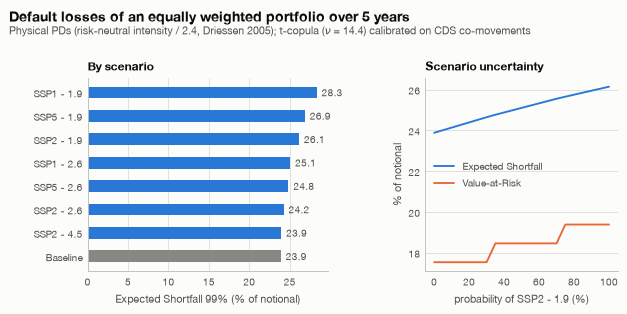

In [11]:
results = replace(results, portfolio=portfolio_res, tables={**results.tables, **portfolio_tables})
show(figures.credit_figures.portfolio)

## Take-aways

- **Risk-free curve.** Socio-economic narratives move it by hundreds of basis points by 2050. Transition policy moves it by a few basis points.
- **Credit spreads.** The transition widens oil & gas spreads. For utilities the sign depends on how each IAM models electrification.
- **Joint repricing.** At revelation the risk-free channel costs 10-year bonds about 0.6% under SSP2-1.9, and its sign depends on whether the central bank reacts to carbon-price inflation. Ignoring it understates the loss of fossil issuers and misses most of the loss of low-carbon ones.
- **Cost of delay.** For oil & gas producers, the later the transition is priced, the larger the jump in spreads.